In [1]:
# ============================================================
# 강판 표면 결함 분류 - 범주화 컬럼 추가 + 학습/검증/테스트 3분할 버전
# ============================================================
# 기반: steel_fault_binned_model.ipynb (범주화 컬럼, 소프트 보팅, 클래스별 확률 보정,
#       부트스트랩 신뢰구간, 묶음 Permutation Importance, 재학습/예측 함수)
#
# [이번에 바꾼 것] 교차검증 대신 학습 / 검증 / 테스트 3분할
#   학습(Train) 60% : 모델 학습
#   검증(Val)   20% : 변수 조합 선택, 하이퍼파라미터 튜닝, 앙상블 선택, 확률 보정
#   테스트(Test) 20% : 위 결정이 모두 끝난 뒤 마지막 1회만 평가
#
#   - 튜닝: RandomizedSearchCV + PredefinedSplit 으로 "학습셋 학습 → 검증셋 점수"
#   - 검증셋 하나는 표본이 ~390개라 점수가 흔들리므로, 변수 조합 비교에
#     부트스트랩 표준편차를 함께 보고 작은 차이는 단순한 쪽을 선택
#   - 과적합 점검: 학습 / 검증 / 테스트 점수를 한 표로 비교
#   - REFIT_ON_TRAIN_VAL = True 이면 선택이 끝난 뒤 학습+검증(80%)으로 다시 학습해
#     테스트 평가 (검증셋 데이터를 버리지 않기 위함). False 이면 학습셋 모델 그대로 평가.
#
# [범주화 컬럼] 범주화할래.ipynb EDA 결과 반영
#       Thickness_Group    : K_Scatch 99% ≤40 / Stains 98.6% 40~60 / Z_Scratch 89.5% 60~80
#                            / Dirtiness 61.8% 80~150
#       Conveyer_Group     : Stains 1354~1362(SD 1.5), Z_Scratch 중앙 1356, K_Scatch 1362
#                            vs Bumps 1624, Pastry 1648
#       Area_Group         : Stains 최대 86 / K_Scatch 중앙 6281 / 나머지 120~210
#       Outside_X_Group    : K_Scatch 중앙 0.113 vs 나머지 ≤0.011
#       Orientation_Group  : K_Scatch·Stains 음수, Pastry 0.667·Dirtiness 0.800
#       Edges_Y_Group      : K_Scatch 중앙 0.474 vs 나머지 0.93~1.0
#       Min_Lum_Group      : K_Scatch 중앙 41 / Stains 115(SD 8.6)
#       Square_Group       : Dirtiness 0.194 / Pastry 0.333 / Bumps·Stains 0.70~0.75
#       Edges_X_Group      : Stains 중앙 1.0 / Dirtiness 0.290
#       Steel_Thickness    : 강종 × 두께구간 조합 (Z_Scratch = A300 90% + 60~80 89.5%)
#
# [주의] 구간 경계는 전체 데이터(테스트 포함) EDA를 보고 정했으므로
#        테스트 점수가 아주 약간 낙관적일 수 있다.
# ============================================================

In [2]:
# ============================================================
# 0. 라이브러리 및 설정
# ============================================================

import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    train_test_split,
    PredefinedSplit,
    RandomizedSearchCV,
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"
N_ITER = 20            # 모델별 무작위 탐색 조합 수 (시간이 부족하면 줄이기)

# 분할 비율: 학습 60 / 검증 20 / 테스트 20
VAL_SIZE = 0.20
TEST_SIZE = 0.20

# True  : 범주화 컬럼을 항상 사용 (요청 사항)
# False : 검증셋 결과로 사용 여부를 자동 결정
FORCE_BINNED = True

# True  : 선택이 끝난 뒤 학습+검증(80%)으로 재학습해 테스트 평가
# False : 학습셋(60%) 모델 그대로 테스트 평가
REFIT_ON_TRAIN_VAL = True

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
              "Dirtiness", "Bumps", "Other_Faults"]
TARGET = "Fault_Type"

LABELS = list(range(len(FAULT_COLS)))
class_to_int = {name: i for i, name in enumerate(FAULT_COLS)}
int_to_class = {i: name for name, i in class_to_int.items()}
STEEL_CODE = {"A300": 0, "A400": 1}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)


def score_row(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, labels=LABELS,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, labels=LABELS,
                                     average="macro", zero_division=0),
        "Macro F1": macro_f1(y_true, y_pred),
    }


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

In [3]:
# ============================================================
# 1. 데이터 불러오기 및 열 병합 (원-핫 구조 검증 포함)
# ============================================================

raw_df = pd.read_csv(DATA_PATH)
print("원본 데이터 크기:", raw_df.shape)
print("결측치:", raw_df.isna().sum().sum(), "/ 중복 행:", raw_df.duplicated().sum())

for cols, label in [(STEEL_COLS, "강종"), (FAULT_COLS, "결함 유형")]:
    missing = [c for c in cols if c not in raw_df.columns]
    if missing:
        raise ValueError(f"{label} 열이 없습니다: {missing}")
    if not raw_df[cols].isin([0, 1]).all().all():
        raise ValueError(f"{label} 열은 0 또는 1이어야 합니다.")
    if not (raw_df[cols].sum(axis=1) == 1).all():
        raise ValueError(f"{label}이(가) 정확히 하나로 정해지지 않는 행이 있습니다.")


def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type, 결함 7열 → Fault_Type (결함 열이 없으면 강종만)"""
    out = data.copy()
    if set(STEEL_COLS).issubset(out.columns):
        pos = out.columns.get_loc("TypeOfSteel_A300")
        steel = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(pos, "Steel_Type", steel)
    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)
    return out


df = merge_columns(raw_df)
print("병합 후 데이터 크기:", df.shape)

print("\n[결함 유형 분포]")
display(df[TARGET].value_counts().reindex(FAULT_COLS).to_frame("count"))


# ============================================================
# 2. 강종 - 결함 유형 관계 (카이제곱 검정, Cramér's V)
# ============================================================

ct = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(ct)
cv_steel = np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))

print("\n[결함 유형 × 강종]")
display(ct)
print(f"Chi2 = {chi2:.1f}, df = {dof}, p = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cv_steel:.3f}")

원본 데이터 크기: (1941, 34)
결측치: 0 / 중복 행: 0
병합 후 데이터 크기: (1941, 27)

[결함 유형 분포]


,count
Fault_Type,
Pastry,158
Z_Scratch,190
K_Scatch,391
Stains,72
Dirtiness,55
Bumps,402
Other_Faults,673



[결함 유형 × 강종]


Steel_Type,A300,A400
Fault_Type,,
Pastry,49,109
Z_Scratch,172,18
K_Scatch,1,390
Stains,1,71
Dirtiness,9,46
Bumps,279,123
Other_Faults,266,407


Chi2 = 667.0, df = 6, p = <0.001, Cramér's V = 0.586


In [4]:
# ============================================================
# 3. 범주화(구간) 정의 - 범주화할래.ipynb EDA 결과 반영
# ============================================================
# pd.cut 은 오른쪽 경계 포함: (40, 60] → 50, 60 포함
# 양 끝을 -inf / inf 로 두어 새 데이터가 범위를 벗어나도 결측이 생기지 않게 함
# ============================================================

INF = np.inf
BIN_SPECS = {
    # 새 컬럼명            : (원본 컬럼, 경계, 라벨)
    "Thickness_Group":   ("Steel_Plate_Thickness", [-INF, 40, 60, 80, 150, INF],
                          ["40 이하", "40~60", "60~80", "80~150", "150 초과"]),
    "Conveyer_Group":    ("Length_of_Conveyer", [-INF, 1350, 1365, 1600, INF],
                          ["1350 이하", "1350~1365", "1365~1600", "1600 초과"]),
    "Area_Group":        ("Pixels_Areas", [-INF, 100, 1000, 5000, INF],
                          ["100 이하", "100~1000", "1000~5000", "5000 초과"]),
    "Outside_X_Group":   ("Outside_X_Index", [-INF, 0.02, 0.05, INF],
                          ["0.02 이하", "0.02~0.05", "0.05 초과"]),
    "Orientation_Group": ("Orientation_Index", [-INF, -0.3, 0.3, 0.6, INF],
                          ["-0.3 이하", "-0.3~0.3", "0.3~0.6", "0.6 초과"]),
    "Edges_Y_Group":     ("Edges_Y_Index", [-INF, 0.7, 0.999, INF],
                          ["0.7 이하", "0.7~0.999", "1.0"]),
    "Min_Lum_Group":     ("Minimum_of_Luminosity", [-INF, 60, 100, INF],
                          ["60 이하", "60~100", "100 초과"]),
    "Square_Group":      ("Square_Index", [-INF, 0.3, 0.6, INF],
                          ["0.3 이하", "0.3~0.6", "0.6 초과"]),
    "Edges_X_Group":     ("Edges_X_Index", [-INF, 0.5, 0.9, INF],
                          ["0.5 이하", "0.5~0.9", "0.9 초과"]),
}
N_THICK = len(BIN_SPECS["Thickness_Group"][2])
BINNED_FEATURES = list(BIN_SPECS) + ["Steel_Thickness"]
EXTRA_FEATURES = ["Luminosity_Range", "Aspect_Ratio", "Perimeter_Area_Ratio"]


def add_binned(out: pd.DataFrame) -> pd.DataFrame:
    """구간 변수를 순서형 정수 코드로 추가 (Steel_Type은 이미 0/1로 변환된 상태)"""
    for new_col, (src, bins, _) in BIN_SPECS.items():
        out[new_col] = pd.cut(out[src], bins=bins, labels=False).astype(int)
    # 강종 × 두께구간: A300 → 0~4, A400 → 5~9
    out["Steel_Thickness"] = out["Steel_Type"] * N_THICK + out["Thickness_Group"]
    return out


def build_features(data: pd.DataFrame, use_extra: bool, use_binned: bool) -> pd.DataFrame:
    out = data.drop(columns=[TARGET], errors="ignore").copy()
    out["Steel_Type"] = out["Steel_Type"].map(STEEL_CODE)
    if out["Steel_Type"].isna().any():
        raise ValueError("Steel_Type에 A300 / A400 이외의 값이 있습니다.")

    if use_extra:
        x_len = out["X_Maximum"] - out["X_Minimum"] + 1
        y_len = out["Y_Maximum"] - out["Y_Minimum"] + 1
        out["Luminosity_Range"] = out["Maximum_of_Luminosity"] - out["Minimum_of_Luminosity"]
        out["Aspect_Ratio"] = x_len / y_len
        out["Perimeter_Area_Ratio"] = (
            (out["X_Perimeter"] + out["Y_Perimeter"]) / out["Pixels_Areas"]
        )
    if use_binned:
        out = add_binned(out)
    return out


def binned_labels(data: pd.DataFrame) -> pd.DataFrame:
    """확인용: 구간을 사람이 읽을 수 있는 라벨로"""
    out = pd.DataFrame(index=data.index)
    for new_col, (src, bins, labels) in BIN_SPECS.items():
        out[new_col] = pd.cut(data[src], bins=bins, labels=labels)
    out["Steel_Thickness"] = data["Steel_Type"].astype(str) + "_" + out["Thickness_Group"].astype(str)
    return out


y_all = df[TARGET].map(class_to_int).to_numpy()

In [5]:
# ============================================================
# 4. 학습 / 검증 / 테스트 분할 (60 / 20 / 20, 층화)
# ============================================================
# 먼저 테스트 20%를 떼고, 남은 80%를 학습 75% : 검증 25%로 나눈다 (→ 60 / 20 / 20)
# ============================================================

idx_trval, idx_test = train_test_split(
    np.arange(len(df)), test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE
)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=VAL_SIZE / (1 - TEST_SIZE),
    stratify=y_all[idx_trval], random_state=RANDOM_STATE
)
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]
y_trval = y_all[idx_trval]

split_dist = pd.DataFrame({
    "Train": pd.Series(y_train).map(int_to_class).value_counts(),
    "Val": pd.Series(y_val).map(int_to_class).value_counts(),
    "Test": pd.Series(y_test).map(int_to_class).value_counts(),
}).reindex(FAULT_COLS)
split_dist.loc["합계"] = split_dist.sum()
print(f"\n학습: {len(idx_train)}개 / 검증: {len(idx_val)}개 / 테스트: {len(idx_test)}개")
display(split_dist)

# 튜닝용: 학습+검증을 이어 붙이고 학습 행은 -1(항상 학습), 검증 행은 0(검증 fold)
# → RandomizedSearchCV 가 "학습셋으로 학습, 검증셋으로 채점"을 한 번만 수행
ps = PredefinedSplit(np.r_[np.full(len(idx_train), -1), np.zeros(len(idx_val), dtype=int)])


def boot_f1(y_true, y_pred, n=1000, seed=RANDOM_STATE):
    """부트스트랩 Macro F1 분포 (평균, 표준편차, 95% 구간)"""
    r = np.random.default_rng(seed)
    s = [macro_f1(y_true[b], y_pred[b])
         for b in (r.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.mean(s), np.std(s), np.percentile(s, [2.5, 97.5])


학습: 1164개 / 검증: 388개 / 테스트: 389개


,Train,Val,Test
Pastry,95,31,32
Z_Scratch,114,38,38
K_Scatch,235,78,78
Stains,43,15,14
Dirtiness,33,11,11
Bumps,241,80,81
Other_Faults,403,135,135
합계,1164,388,389


In [6]:
# ============================================================
# 5. 범주화 컬럼 점검 (학습 데이터만 사용)
# ============================================================
# 구간별 클래스 구성이 학습 데이터에서도 EDA와 같은 모양인지,
# 구간 변수 하나만으로 결함 유형과 얼마나 연관되는지(Cramér's V) 확인한다.
# 검증/테스트 데이터는 보지 않는다.
# ============================================================

tr_labels = binned_labels(df.iloc[idx_train])
tr_target = df.iloc[idx_train][TARGET]

bin_check = []
for col in BINNED_FEATURES:
    src = BIN_SPECS[col][0] if col in BIN_SPECS else "Steel_Type × Thickness"
    sizes = tr_labels[col].value_counts()
    bin_check.append({
        "범주화 컬럼": col,
        "원본 컬럼": src,
        "구간 수": tr_labels[col].nunique(),
        "최소 구간 크기": int(sizes[sizes > 0].min()),
        "Cramér's V": cramers_v(tr_labels[col], tr_target),
    })
bin_check_df = (pd.DataFrame(bin_check)
                .sort_values("Cramér's V", ascending=False).reset_index(drop=True))
print("[범주화 컬럼 - 결함 유형 연관성 (학습 데이터)]")
display(bin_check_df.round(3))

for col in bin_check_df["범주화 컬럼"].head(3):
    print(f"\n[{col}] 구간별 결함 유형 비율(%) - 행 합계 100")
    display(pd.crosstab(tr_labels[col], tr_target, normalize="index")
            .reindex(columns=FAULT_COLS).mul(100).round(1))

[범주화 컬럼 - 결함 유형 연관성 (학습 데이터)]


,범주화 컬럼,원본 컬럼,구간 수,최소 구간 크기,Cramér's V
0,Outside_X_Group,Outside_X_Index,3,97,0.599
1,Min_Lum_Group,Minimum_of_Luminosity,3,277,0.535
2,Thickness_Group,Steel_Plate_Thickness,5,110,0.514
3,Edges_Y_Group,Edges_Y_Index,3,334,0.508
4,Area_Group,Pixels_Areas,4,104,0.498
5,Steel_Thickness,Steel_Type × Thickness,9,24,0.489
6,Orientation_Group,Orientation_Index,4,208,0.386
7,Square_Group,Square_Index,3,215,0.366
8,Conveyer_Group,Length_of_Conveyer,4,19,0.347
9,Edges_X_Group,Edges_X_Index,3,150,0.295



[Outside_X_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Outside_X_Group,,,,,,,
0.02 이하,11.0,11.6,3.3,5.1,3.9,25.7,39.3
0.02~0.05,2.1,14.4,9.3,0.0,0.0,21.6,52.6
0.05 초과,0.0,0.9,88.8,0.0,0.0,1.3,9.0



[Min_Lum_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Min_Lum_Group,,,,,,,
60 이하,8.3,3.6,68.6,0.0,0.7,4.7,14.1
60~100,12.8,13.0,2.0,0.4,2.4,31.6,37.7
100 초과,2.3,10.2,8.9,10.4,4.8,18.3,45.2



[Thickness_Group] 구간별 결함 유형 비율(%) - 행 합계 100


Fault_Type,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
Thickness_Group,,,,,,,
40 이하,5.1,1.6,54.3,0.0,1.9,10.3,26.8
40~60,9.1,0.0,0.9,38.2,0.0,33.6,18.2
60~80,3.3,28.5,0.3,0.0,0.9,32.3,34.7
80~150,25.6,1.2,0.0,0.6,13.1,20.8,38.7
150 초과,7.5,7.5,0.0,0.0,0.0,13.3,71.7


In [7]:
# ============================================================
# 6. 변수 조합 결정 (학습셋 학습 → 검증셋 평가)
# ============================================================
# 원본 / +파생 / +범주화 / +파생+범주화 네 조합을 RF와 LightGBM으로 비교.
# 모델 난수에 따른 흔들림을 줄이려고 시드 3개로 학습해 확률을 평균한다.
# 검증셋 하나의 표본 흔들림은 부트스트랩 표준편차로 같이 표시한다.
# ============================================================

probes = {
    "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1),
    "LGBM": LGBMClassifier(objective="multiclass", n_jobs=-1, verbose=-1,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8),
}
combos = {
    "원본만": (False, False),
    "원본 + 파생": (True, False),
    "원본 + 범주화": (False, True),
    "원본 + 파생 + 범주화": (True, True),
}
PROBE_SEEDS = [0, 1, 2]

fs_rows = []
for cname, (ue, ub) in combos.items():
    X_tmp = build_features(df, ue, ub)
    Xtr, Xva = X_tmp.iloc[idx_train], X_tmp.iloc[idx_val]
    row = {"조합": cname, "변수 수": X_tmp.shape[1]}
    P_all = []
    for pname, probe in probes.items():
        P = np.mean([clone(probe).set_params(random_state=s).fit(Xtr, y_train).predict_proba(Xva)
                     for s in PROBE_SEEDS], axis=0)
        P_all.append(P)
        row[f"{pname} Val F1"] = macro_f1(y_val, P.argmax(axis=1))
    pred = np.mean(P_all, axis=0).argmax(axis=1)
    mean_b, sd_b, _ = boot_f1(y_val, pred)
    row["두 모델 평균 Val F1"] = macro_f1(y_val, pred)
    row["부트스트랩 SD"] = sd_b
    fs_rows.append(row)

fs_df = pd.DataFrame(fs_rows).set_index("조합")
print("[변수 조합별 검증셋 Macro F1]")
display(fs_df.round(4))

COL = "두 모델 평균 Val F1"
base_score, base_sd = fs_df.loc["원본만", [COL, "부트스트랩 SD"]]


def better(a, b):
    # a 가 b 보다 부트스트랩 SD 의 절반 이상 좋을 때만 채택 (작은 차이는 단순한 쪽)
    return fs_df.loc[a, COL] - fs_df.loc[b, COL] > 0.5 * fs_df.loc[b, "부트스트랩 SD"]


if FORCE_BINNED:
    USE_BINNED = True
    USE_EXTRA = better("원본 + 파생 + 범주화", "원본 + 범주화")
else:
    USE_BINNED = better("원본 + 범주화", "원본만") or better("원본 + 파생 + 범주화", "원본만")
    if USE_BINNED:
        USE_EXTRA = better("원본 + 파생 + 범주화", "원본 + 범주화")
    else:
        USE_EXTRA = better("원본 + 파생", "원본만")

print(f"범주화 컬럼 추가 효과(원본 대비, 검증셋): "
      f"{fs_df.loc['원본 + 범주화', COL] - base_score:+.4f}  (부트스트랩 SD {base_sd:.4f})")
print(f"→ 범주화 사용: {USE_BINNED} {'(FORCE_BINNED)' if FORCE_BINNED else ''}"
      f" / 파생변수 사용: {USE_EXTRA}")

X_all = build_features(df, USE_EXTRA, USE_BINNED)
feature_cols = X_all.columns.tolist()
X_train, X_val, X_test = X_all.iloc[idx_train], X_all.iloc[idx_val], X_all.iloc[idx_test]
X_trval = pd.concat([X_train, X_val])          # PredefinedSplit 순서와 동일 (학습 → 검증)
y_trval_ps = np.r_[y_train, y_val]
print(f"최종 입력 변수 {len(feature_cols)}개")

[변수 조합별 검증셋 Macro F1]


,변수 수,RF Val F1,LGBM Val F1,두 모델 평균 Val F1,부트스트랩 SD
조합,,,,,
원본만,26,0.7585,0.7707,0.7636,0.0295
원본 + 파생,29,0.7699,0.7583,0.7498,0.0299
원본 + 범주화,36,0.7836,0.7755,0.7830,0.0282
원본 + 파생 + 범주화,39,0.7646,0.7655,0.7540,0.0300


범주화 컬럼 추가 효과(원본 대비, 검증셋): +0.0195  (부트스트랩 SD 0.0295)
→ 범주화 사용: True (FORCE_BINNED) / 파생변수 사용: False
최종 입력 변수 36개


In [8]:
# ============================================================
# 7. 모델 및 탐색 공간
# ============================================================
# 선형/거리 기반 모델은 이전 비교에서 Macro F1이 0.07~0.17 낮아 트리 계열만 사용.
# 범주화 컬럼은 순서형 정수라 트리 모델에 그대로 넣는다.
# 튜닝은 학습셋으로 학습하고 검증셋 점수로 고른다.
# ============================================================

models = {
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1),
    "LightGBM": LGBMClassifier(objective="multiclass", random_state=RANDOM_STATE,
                               n_jobs=1, verbose=-1),
    "CatBoost": CatBoostClassifier(loss_function="MultiClass", random_seed=RANDOM_STATE,
                                   verbose=0, allow_writing_files=False, thread_count=1),
}

param_spaces = {
    "Random Forest": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "Extra Trees": {
        "n_estimators": [300, 500, 700],
        "max_depth": [None, 10, 15, 20, 30],
        "min_samples_split": [2, 5, 9],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.3, 0.5, 0.8],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 700, 1000],
        "learning_rate": [0.02, 0.03, 0.05, 0.1],
        "num_leaves": [7, 15, 22, 31],
        "max_depth": [-1, 5, 7, 10],
        "min_child_samples": [5, 10, 20, 33],
        "subsample": [0.6, 0.8, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "reg_lambda": [0, 0.01, 1, 5],
        "class_weight": [None, "balanced"],
    },
    "CatBoost": {
        "iterations": [300, 500, 700],
        "depth": [4, 5, 6, 7],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [1, 3, 5, 7],
        "auto_class_weights": [None, "Balanced", "SqrtBalanced"],
    },
}

In [9]:
# ============================================================
# 8. 하이퍼파라미터 튜닝 (학습셋 학습 → 검증셋 Macro F1)
# ============================================================

tuned = {}
tuning_rows = []

for name, model in models.items():
    print(f"\n{name} 튜닝 중... ({N_ITER}개 조합, 학습셋 → 검증셋)")
    start = time.time()
    search = RandomizedSearchCV(
        model, param_spaces[name], n_iter=N_ITER, scoring="f1_macro",
        cv=ps, random_state=RANDOM_STATE, n_jobs=-1, refit=False,
    )
    search.fit(X_trval, y_trval_ps)
    tuned[name] = clone(model).set_params(**search.best_params_)

    tuning_rows.append({
        "Model": name,
        "Val Macro F1": search.best_score_,
        "Best Params": search.best_params_,
        "Time(s)": round(time.time() - start, 1),
    })
    print(f"  Val Macro F1 = {search.best_score_:.4f} | {search.best_params_}")

tuning_df = (pd.DataFrame(tuning_rows)
             .sort_values("Val Macro F1", ascending=False).reset_index(drop=True))
print("\n[튜닝 결과]")
display(tuning_df)


Random Forest 튜닝 중... (20개 조합, 학습셋 → 검증셋)
  Val Macro F1 = 0.8056 | {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15, 'class_weight': 'balanced'}

Extra Trees 튜닝 중... (20개 조합, 학습셋 → 검증셋)
  Val Macro F1 = 0.8198 | {'n_estimators': 700, 'min_samples_split': 9, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15, 'class_weight': 'balanced'}

LightGBM 튜닝 중... (20개 조합, 학습셋 → 검증셋)
  Val Macro F1 = 0.8064 | {'subsample_freq': 1, 'subsample': 1.0, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 33, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8, 'class_weight': 'balanced'}

CatBoost 튜닝 중... (20개 조합, 학습셋 → 검증셋)
  Val Macro F1 = 0.8108 | {'learning_rate': 0.1, 'l2_leaf_reg': 7, 'iterations': 500, 'depth': 7, 'auto_class_weights': 'Balanced'}

[튜닝 결과]


,Model,Val Macro F1,Best Params,Time(s)
0,Extra Trees,0.819753,"{'n_estimators': 700, 'min_samples_split': 9, ...",2.8
1,CatBoost,0.810819,"{'learning_rate': 0.1, 'l2_leaf_reg': 7, 'iter...",81.0
2,LightGBM,0.806422,"{'subsample_freq': 1, 'subsample': 1.0, 'reg_l...",2.9
3,Random Forest,0.805635,"{'n_estimators': 300, 'min_samples_split': 5, ...",8.6


In [10]:
# ============================================================
# 9. 검증셋 확률 예측 + 앙상블 후보 + 클래스별 확률 보정
# ============================================================
# 튜닝된 모델을 학습셋으로 학습해 검증셋 확률을 얻고,
# 앙상블 조합과 클래스별 배율은 이 확률로만 결정한다 (테스트는 건드리지 않음).
# 튜닝·선택·보정을 모두 같은 검증셋에서 했으므로 검증 점수는 낙관적이다
# → 성능 판단은 반드시 11단계의 테스트 점수로 한다.
# ============================================================

fitted_train = {name: clone(est).fit(X_train, y_train) for name, est in tuned.items()}
val_proba = {name: m.predict_proba(X_val) for name, m in fitted_train.items()}


def tune_class_scale(P, y, grid=np.round(np.arange(0.5, 3.01, 0.1), 2), n_rounds=3):
    """
    예측 확률에 클래스별 배율을 곱해 argmax 했을 때 Macro F1이 최대가 되는 배율 탐색.
    배율 > 1 이면 그 클래스를 더 자주 예측(재현율↑ 정밀도↓), < 1 이면 반대.
    """
    w = np.ones(P.shape[1])
    best = macro_f1(y, P.argmax(axis=1))
    for _ in range(n_rounds):
        improved = False
        for k in range(P.shape[1]):
            for g in grid:
                trial = w.copy()
                trial[k] = g
                s = macro_f1(y, (P * trial).argmax(axis=1))
                if s > best + 1e-9:
                    best, w, improved = s, trial, True
        if not improved:
            break
    return w, best


ranked = tuning_df["Model"].tolist()
candidates = {name: [name] for name in ranked}
candidates["앙상블(상위 2)"] = ranked[:2]
candidates["앙상블(상위 3)"] = ranked[:3]
candidates["앙상블(전체 4)"] = ranked

cand_rows = []
cand_scale = {}
for cname, members in candidates.items():
    P = np.mean([val_proba[m] for m in members], axis=0)
    raw = macro_f1(y_val, P.argmax(axis=1))
    w, scaled = tune_class_scale(P, y_val)
    cand_scale[cname] = w
    cand_rows.append({"Candidate": cname, "Val Macro F1": raw,
                      "Val Macro F1 (확률 보정)": scaled})

cand_df = (pd.DataFrame(cand_rows)
           .sort_values("Val Macro F1 (확률 보정)", ascending=False).reset_index(drop=True))
print("\n[후보별 검증셋 성능]")
display(cand_df.round(4))


[후보별 검증셋 성능]


,Candidate,Val Macro F1,Val Macro F1 (확률 보정)
0,앙상블(상위 3),0.8154,0.8488
1,앙상블(전체 4),0.8220,0.8460
2,앙상블(상위 2),0.8188,0.8456
3,Extra Trees,0.8198,0.8426
4,LightGBM,0.8064,0.8392
5,CatBoost,0.8108,0.8353
6,Random Forest,0.8056,0.8278


In [11]:
# ============================================================
# 10. 최종 후보 선택 및 최종 모델 학습
# ============================================================
# 보정은 검증셋에 맞춰 찾은 값이라 그 자체로 낙관적이다.
# 보정 이득이 0.005 미만이면 보정 없이 사용한다.
# ============================================================

class ScaledSoftVoting(BaseEstimator, ClassifierMixin):
    """여러 모델의 확률 평균 + 클래스별 배율 보정"""

    def __init__(self, estimators, class_scale=None):
        self.estimators = estimators
        self.class_scale = class_scale

    def fit(self, X, y):
        self.estimators_ = [clone(e).fit(X, y) for e in self.estimators]
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        P = np.mean([e.predict_proba(X) for e in self.estimators_], axis=0)
        if self.class_scale is not None:
            P = P * np.asarray(self.class_scale)
            P = P / P.sum(axis=1, keepdims=True)
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


best_row = cand_df.iloc[0]
best_cand = best_row["Candidate"]
use_scale = (best_row["Val Macro F1 (확률 보정)"] - best_row["Val Macro F1"]) >= 0.005
final_scale = cand_scale[best_cand] if use_scale else None

print("\n최종 후보:", best_cand, "| 구성:", candidates[best_cand])
print("확률 보정 사용:", use_scale)
if use_scale:
    display(pd.Series(final_scale, index=FAULT_COLS, name="클래스 배율").round(2))


def make_final(estimators=None):
    return ScaledSoftVoting(
        estimators or [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
    )


# 학습셋만으로 학습한 모델 (과적합 점검용, REFIT_ON_TRAIN_VAL=False 이면 최종 모델)
train_model = make_final().fit(X_train, y_train)

if REFIT_ON_TRAIN_VAL:
    X_fit, y_fit = pd.concat([X_train, X_val]), np.r_[y_train, y_val]
    final_model = make_final().fit(X_fit, y_fit)
    print("최종 모델: 학습+검증 데이터로 재학습")
else:
    X_fit, y_fit = X_train, y_train
    final_model = train_model
    print("최종 모델: 학습 데이터만 사용")


최종 후보: 앙상블(상위 3) | 구성: ['Extra Trees', 'CatBoost', 'LightGBM']
확률 보정 사용: True


Pastry          2.7
Z_Scratch       0.8
K_Scatch        1.4
Stains          1.0
Dirtiness       0.6
Bumps           1.0
Other_Faults    1.6
Name: 클래스 배율, dtype: float64

최종 모델: 학습+검증 데이터로 재학습


In [12]:
# ============================================================
# 11. 테스트 평가 (마지막 1회) + 학습/검증/테스트 비교
# ============================================================

y_pred = final_model.predict(X_test)
test_scores = score_row(y_test, y_pred)

print("\n" + "=" * 60)
print(f"최종 테스트 결과 - {best_cand}{' + 확률 보정' if use_scale else ''}"
      f"{' + 범주화 컬럼' if USE_BINNED else ''}"
      f"{' (학습+검증 재학습)' if REFIT_ON_TRAIN_VAL else ''}")
print("=" * 60)
display(pd.DataFrame([test_scores]).round(4))

_, _, (lo, hi) = boot_f1(y_test, y_pred)
print(f"테스트 Macro F1 95% 신뢰구간: [{lo:.3f}, {hi:.3f}]")

print("\n[Classification Report - Test]")
print(classification_report(y_test, y_pred, labels=LABELS,
                            target_names=FAULT_COLS, digits=4, zero_division=0))

# 과적합 점검: 같은 모델(학습셋으로 학습)의 학습 / 검증 / 테스트 점수
# - 학습 ≫ 검증·테스트 : 과적합 (트리 앙상블은 학습 점수가 1에 가까운 것이 보통)
# - 검증 ≫ 테스트     : 검증셋에 맞춰 고른 선택/보정이 과하게 맞춰졌을 가능성
gap_df = pd.DataFrame([
    {"데이터": "학습 (Train)", **score_row(y_train, train_model.predict(X_train))},
    {"데이터": "검증 (Val, 선택·보정에 사용)", **score_row(y_val, train_model.predict(X_val))},
    {"데이터": "테스트 (Test)", **score_row(y_test, train_model.predict(X_test))},
]).set_index("데이터")
print("[학습셋으로 학습한 모델의 데이터별 점수]")
display(gap_df.round(4))
if REFIT_ON_TRAIN_VAL:
    print(f"학습+검증 재학습 모델의 테스트 Macro F1: {test_scores['Macro F1']:.4f} "
          f"(학습셋만: {gap_df.iloc[2]['Macro F1']:.4f})")

# 참고용: 다른 후보들의 테스트 성능 (이것을 보고 선택을 바꾸지 않는다)
ref_rows = []
for cname, members in candidates.items():
    m = ScaledSoftVoting([tuned[x] for x in members]).fit(X_fit, y_fit)
    ref_rows.append({"Candidate": cname,
                     "Val Macro F1 (보정 없음)": cand_df.set_index("Candidate")
                     .loc[cname, "Val Macro F1"],
                     "Test Macro F1 (보정 없음)": macro_f1(y_test, m.predict(X_test))})
print("[참고] 후보별 검증 / 테스트 Macro F1")
display(pd.DataFrame(ref_rows).round(4))


최종 테스트 결과 - 앙상블(상위 3) + 확률 보정 + 범주화 컬럼 (학습+검증 재학습)


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
0,0.7918,0.8402,0.8134,0.8402,0.8155


테스트 Macro F1 95% 신뢰구간: [0.769, 0.856]

[Classification Report - Test]
              precision    recall  f1-score   support

      Pastry     0.5000    0.9375    0.6522        32
   Z_Scratch     0.8947    0.8947    0.8947        38
    K_Scatch     0.9868    0.9615    0.9740        78
      Stains     0.9286    0.9286    0.9286        14
   Dirtiness     0.8182    0.8182    0.8182        11
       Bumps     0.8095    0.6296    0.7083        81
Other_Faults     0.7559    0.7111    0.7328       135

    accuracy                         0.7918       389
   macro avg     0.8134    0.8402    0.8155       389
weighted avg     0.8139    0.7918    0.7947       389

[학습셋으로 학습한 모델의 데이터별 점수]


,Accuracy,Balanced Acc,Macro Precision,Macro Recall,Macro F1
데이터,,,,,
학습 (Train),0.9845,0.9917,0.9783,0.9917,0.9842
"검증 (Val, 선택·보정에 사용)",0.8273,0.8515,0.8499,0.8515,0.8488
테스트 (Test),0.8072,0.8200,0.8013,0.8200,0.8055


학습+검증 재학습 모델의 테스트 Macro F1: 0.8155 (학습셋만: 0.8055)
[참고] 후보별 검증 / 테스트 Macro F1


,Candidate,Val Macro F1 (보정 없음),Test Macro F1 (보정 없음)
0,Extra Trees,0.8198,0.8117
1,CatBoost,0.8108,0.8061
2,LightGBM,0.8064,0.8050
3,Random Forest,0.8056,0.8056
4,앙상블(상위 2),0.8188,0.8141
5,앙상블(상위 3),0.8154,0.8195
6,앙상블(전체 4),0.8220,0.8259


In [13]:
# ============================================================
# 12. [참고] 범주화 컬럼 유무 비교 (같은 모델 구성 · 같은 파라미터 · 같은 보정)
# ============================================================
# 범주화 컬럼만 빼고 나머지를 모두 동일하게 둔 모델과 검증셋·테스트셋에서 비교한다.
# 파라미터는 범주화 포함 데이터로 튜닝한 값이라 '빼는 쪽'이 약간 불리할 수 있다.
# 같은 행에서 짝지어 부트스트랩하므로 차이의 신뢰구간을 직접 볼 수 있다.
# ============================================================

if USE_BINNED:
    keep_cols = [c for c in feature_cols if c not in BINNED_FEATURES]

    # 검증셋 비교 (학습셋으로 학습)
    nb_train = make_final().fit(X_train[keep_cols], y_train)
    val_with = train_model.predict(X_val)
    val_without = nb_train.predict(X_val[keep_cols])

    # 테스트셋 비교 (최종 모델과 같은 데이터로 학습)
    nb_final = make_final().fit(X_fit[keep_cols], y_fit)
    y_pred_nb = nb_final.predict(X_test[keep_cols])

    def paired_diff(y_true, a, b, n=1000):
        r = np.random.default_rng(RANDOM_STATE)
        d = []
        for _ in range(n):
            idx = r.integers(0, len(y_true), len(y_true))
            d.append(macro_f1(y_true[idx], a[idx]) - macro_f1(y_true[idx], b[idx]))
        return np.percentile(d, [2.5, 97.5])

    rows = []
    for split_name, yt, a, b in [("검증", y_val, val_with, val_without),
                                 ("테스트", y_test, y_pred, y_pred_nb)]:
        d_lo, d_hi = paired_diff(yt, a, b)
        rows.append({"데이터": split_name,
                     "F1 포함": macro_f1(yt, a), "F1 제외": macro_f1(yt, b),
                     "차이(포함-제외)": macro_f1(yt, a) - macro_f1(yt, b),
                     "차이 95% 하한": d_lo, "차이 95% 상한": d_hi})
    display(pd.DataFrame(rows).set_index("데이터").round(4))
    print("  → 구간이 0을 포함하면 범주화 효과가 있다고 단정하기 어렵다.")

    per_class = pd.DataFrame({
        "Test F1 (포함)": f1_score(y_test, y_pred, labels=LABELS, average=None, zero_division=0),
        "Test F1 (제외)": f1_score(y_test, y_pred_nb, labels=LABELS, average=None, zero_division=0),
    }, index=FAULT_COLS)
    per_class["차이"] = per_class["Test F1 (포함)"] - per_class["Test F1 (제외)"]
    print("\n[클래스별 테스트 F1 비교]")
    display(per_class.round(4))

,F1 포함,F1 제외,차이(포함-제외),차이 95% 하한,차이 95% 상한
데이터,,,,,
검증,0.8488,0.8162,0.0327,0.0018,0.0737
테스트,0.8155,0.8170,-0.0015,-0.0171,0.0139


  → 구간이 0을 포함하면 범주화 효과가 있다고 단정하기 어렵다.

[클래스별 테스트 F1 비교]


,Test F1 (포함),Test F1 (제외),차이
Pastry,0.6522,0.6522,0.0000
Z_Scratch,0.8947,0.9211,-0.0263
K_Scatch,0.9740,0.9740,0.0000
Stains,0.9286,0.9286,0.0000
Dirtiness,0.8182,0.8182,0.0000
Bumps,0.7083,0.6897,0.0187
Other_Faults,0.7328,0.7356,-0.0028


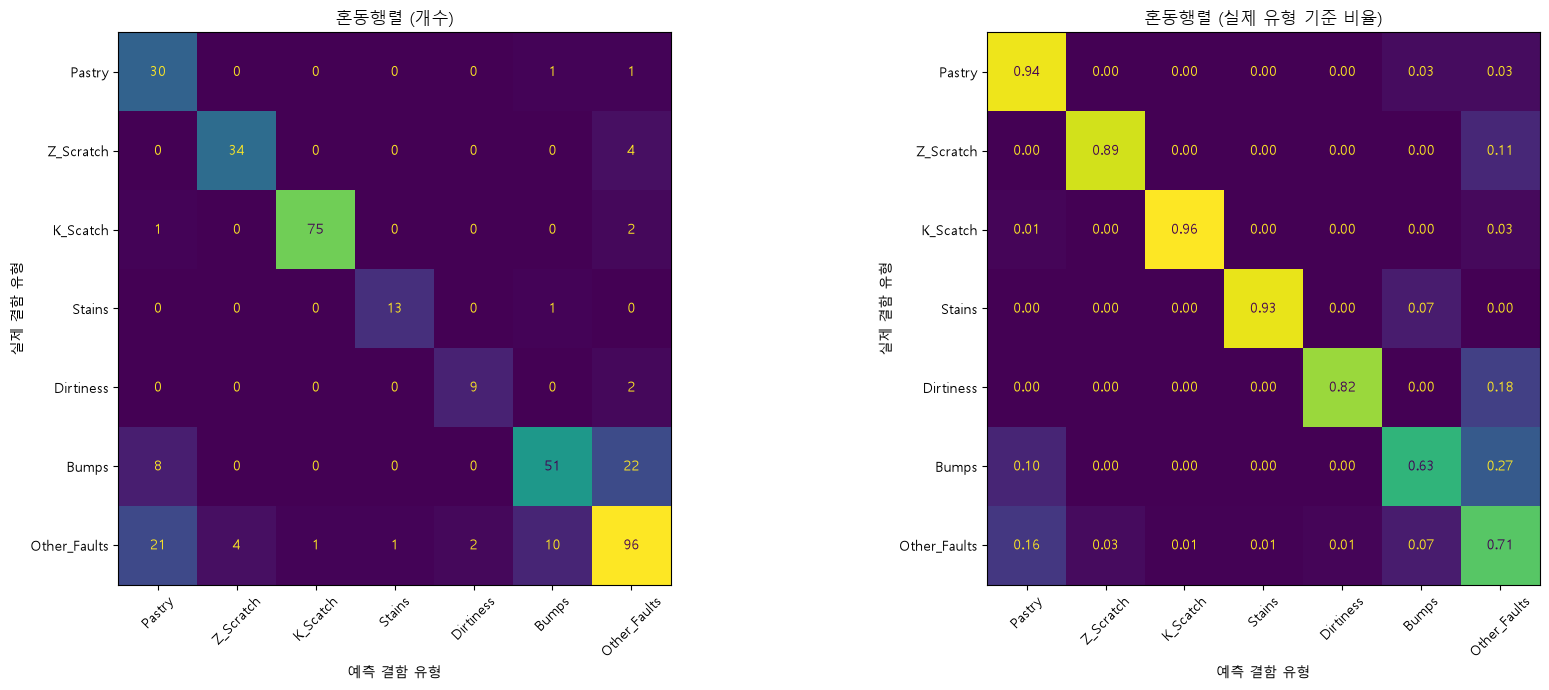


오분류: 81 / 389 (20.82%)


Count
Actual       Predicted          
Bumps        Other_Faults     22
Other_Faults Pastry           21
             Bumps            10
Bumps        Pastry            8
Other_Faults Z_Scratch         4
Z_Scratch    Other_Faults      4
Dirtiness    Other_Faults      2
K_Scatch     Other_Faults      2
Other_Faults Dirtiness         2
K_Scatch     Pastry            1

In [14]:
# ============================================================
# 13. 혼동행렬 및 오분류 분석
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS),
                       display_labels=FAULT_COLS).plot(
    ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title("혼동행렬 (개수)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true"),
                       display_labels=FAULT_COLS).plot(
    ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("혼동행렬 (실제 유형 기준 비율)")
for ax in axes:
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

test_result = pd.DataFrame({
    "Actual": [int_to_class[i] for i in y_test],
    "Predicted": [int_to_class[i] for i in y_pred],
    "Confidence": final_model.predict_proba(X_test).max(axis=1),
}, index=X_test.index)
misclassified = test_result[test_result["Actual"] != test_result["Predicted"]]

print(f"\n오분류: {len(misclassified)} / {len(y_test)} ({len(misclassified) / len(y_test):.2%})")
display(misclassified.groupby(["Actual", "Predicted"]).size()
        .sort_values(ascending=False).head(10).to_frame("Count"))

,Feature,구분,Importance Mean,Importance SD
0,Length_of_Conveyer,원본,0.0889,0.0196
1,Steel_Thickness,범주화,0.0610,0.0106
2,Steel_Plate_Thickness,원본,0.0251,0.0074
3,Minimum_of_Luminosity,원본,0.0213,0.0142
4,Edges_Index,원본,0.0206,0.0084
5,Y_Maximum,원본,0.0188,0.0052
6,Y_Minimum,원본,0.0175,0.0067
7,Maximum_of_Luminosity,원본,0.0122,0.0084
8,X_Minimum,원본,0.0110,0.0119
9,Steel_Type,원본,0.0109,0.0058


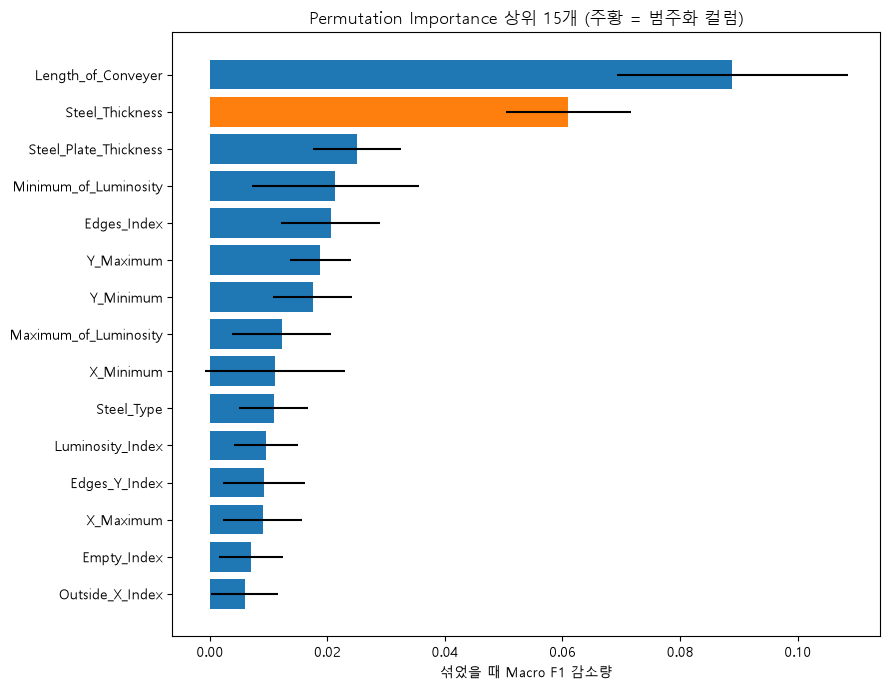


[묶음 Permutation Importance - 원본과 범주화 컬럼을 함께 섞음]


,묶음,Importance Mean,Importance SD
0,Steel_Type + Thickness 묶음,0.2677,0.0186
1,Length_of_Conveyer (+Conveyer_Group),0.1262,0.0188
2,Steel_Plate_Thickness (+Thickness_Group),0.0504,0.0109
3,Minimum_of_Luminosity (+Min_Lum_Group),0.0340,0.0133
4,Orientation_Index (+Orientation_Group),0.0231,0.0123
5,Outside_X_Index (+Outside_X_Group),0.0112,0.0120
6,Square_Index (+Square_Group),0.0108,0.0118
7,Edges_Y_Index (+Edges_Y_Group),0.0069,0.0107
8,Pixels_Areas (+Area_Group),0.0052,0.0026
9,Edges_X_Index (+Edges_X_Group),-0.0171,0.0073


In [15]:
# ============================================================
# 14. 변수 중요도 (Permutation Importance, 테스트 데이터)
# ============================================================
# 범주화 컬럼은 원본과 정보가 겹치므로 하나만 섞으면 다른 쪽이 대신해
# 중요도가 작게 나올 수 있다. 그래서 "원본 + 그 범주화 컬럼"을 함께 섞은
# 묶음 중요도도 같이 본다.
# ============================================================

perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = (pd.DataFrame({
    "Feature": feature_cols,
    "구분": ["범주화" if c in BINNED_FEATURES else
             ("파생" if c in EXTRA_FEATURES else "원본") for c in feature_cols],
    "Importance Mean": perm.importances_mean,
    "Importance SD": perm.importances_std,
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True))
display(importance_df.head(20).round(4))

top = importance_df.head(15).iloc[::-1]
colors = ["tab:orange" if g == "범주화" else "tab:blue" for g in top["구분"]]
plt.figure(figsize=(9, 7))
plt.barh(top["Feature"], top["Importance Mean"], xerr=top["Importance SD"], color=colors)
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title("Permutation Importance 상위 15개 (주황 = 범주화 컬럼)")
plt.tight_layout()
plt.show()

if USE_BINNED:
    base_f1 = macro_f1(y_test, y_pred)
    groups = {f"{src} (+{new})": [src, new] for new, (src, _, _) in BIN_SPECS.items()}
    groups["Steel_Type + Thickness 묶음"] = ["Steel_Type", "Steel_Plate_Thickness",
                                            "Thickness_Group", "Steel_Thickness"]
    g_rng = np.random.default_rng(RANDOM_STATE)
    g_rows = []
    for gname, cols in groups.items():
        drops = []
        for _ in range(10):
            Xp = X_test.copy()
            perm_idx = g_rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[perm_idx]      # 같은 순서로 함께 섞어 관계 유지
            drops.append(base_f1 - macro_f1(y_test, final_model.predict(Xp)))
        g_rows.append({"묶음": gname, "Importance Mean": np.mean(drops),
                       "Importance SD": np.std(drops)})
    print("\n[묶음 Permutation Importance - 원본과 범주화 컬럼을 함께 섞음]")
    display(pd.DataFrame(g_rows).sort_values("Importance Mean", ascending=False)
            .reset_index(drop=True).round(4))

In [16]:
# ============================================================
# 15. 전체 데이터로 재학습 및 저장
# ============================================================
# 평가가 끝났으므로 배포용은 학습+검증+테스트 전체(100%)로 다시 학습한다.
# (테스트 점수는 위 11단계 값을 보고서에 사용)
# ============================================================

deploy_model = ScaledSoftVoting(
    [tuned[m] for m in candidates[best_cand]], class_scale=final_scale
).fit(X_all, y_all)

joblib.dump({
    "model": deploy_model,
    "candidate": best_cand,
    "members": candidates[best_cand],
    "params": {m: tuned[m].get_params() for m in candidates[best_cand]},
    "class_scale": None if final_scale is None else final_scale.tolist(),
    "use_extra_features": USE_EXTRA,
    "use_binned_features": USE_BINNED,
    "bin_specs": BIN_SPECS,
    "feature_cols": feature_cols,
    "class_names": FAULT_COLS,
    "test_scores": test_scores,
    "split_sizes": {"train": len(idx_train), "val": len(idx_val), "test": len(idx_test)},
    "refit_on_train_val": REFIT_ON_TRAIN_VAL,
}, "steel_fault_model_binned_3split.joblib")
print("\n저장 완료: steel_fault_model_binned_3split.joblib")


저장 완료: steel_fault_model_binned_3split.joblib


In [17]:
# ============================================================
# 16. 새 데이터 예측 함수
# ============================================================
# 원본 형식(TypeOfSteel_A300/A400) 또는 병합 형식(Steel_Type) 모두 입력 가능.
# ScaledSoftVoting 클래스와 build_features 가 정의된 환경에서 불러와야 한다.
# 구간 경계는 저장된 bin_specs 를 사용하므로 학습 때와 똑같이 나뉜다.
# ============================================================

def predict_faults(new_data: pd.DataFrame,
                   model_path: str = "steel_fault_model_binned_3split.joblib") -> pd.DataFrame:
    global BIN_SPECS
    bundle = joblib.load(model_path)
    names = bundle["class_names"]
    BIN_SPECS = bundle.get("bin_specs", BIN_SPECS)
    merged = merge_columns(new_data.drop(columns=names, errors="ignore"))
    X_new = build_features(merged, bundle["use_extra_features"],
                           bundle.get("use_binned_features", False))[bundle["feature_cols"]]

    proba = bundle["model"].predict_proba(X_new)
    out = pd.DataFrame(proba, columns=[f"prob_{n}" for n in names], index=new_data.index)
    out.insert(0, "predicted_fault", [names[i] for i in proba.argmax(axis=1)])
    out.insert(1, "confidence", proba.max(axis=1))
    return out


demo = predict_faults(raw_df.iloc[idx_test[:5]])
demo.insert(0, "actual_fault", df.iloc[idx_test[:5]][TARGET].values)
print("\n[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]")
display(demo.round(3))


[예측 함수 동작 확인 - 전체 데이터로 재학습한 모델이므로 성능 지표 아님]


,actual_fault,predicted_fault,confidence,prob_Pastry,prob_Z_Scratch,prob_K_Scatch,prob_Stains,prob_Dirtiness,prob_Bumps,prob_Other_Faults
904,Bumps,Bumps,0.964,0.014,0.000,0.000,0.000,0.000,0.964,0.021
492,K_Scatch,K_Scatch,0.999,0.000,0.000,0.999,0.000,0.000,0.000,0.001
232,Z_Scratch,Z_Scratch,0.967,0.002,0.967,0.000,0.001,0.000,0.003,0.027
1093,Bumps,Bumps,0.721,0.034,0.001,0.006,0.000,0.002,0.721,0.235
803,Stains,Stains,0.995,0.000,0.000,0.000,0.995,0.000,0.001,0.003
